     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 92.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.

Dataset loaded successfully!
Original Dataset Shape: (1600000, 6)

First 5 Records:
   target                                               text
0       0  @switchfoot http://twitpic.com/2y1zl - Awww, t...
1       0  is upset that he can't update his Facebook by ...
2       0  @Kenichan I dived many times for the ball. Man...
3       0    my whole body feels itchy and like its on fire 
4       0  @nationwideclass no, it's not behaving at all....

Sentiment Distribution:
target
0    800000
4    800000
Name: count, dtype: int64

Sampled Dataset Shape: (49890, 7)

Original Tweet

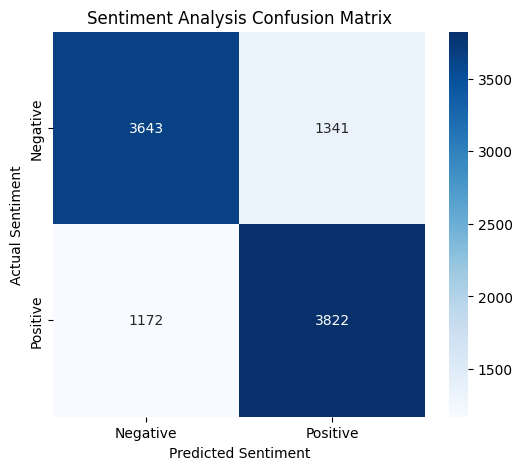


NAMED ENTITY RECOGNITION

Tweet 1:
*_* freaky. yet sad. 

Named Entities:
No named entities detected.

Tweet 2:
@chynnasaur hell yeaaah. why aren't you going to atl 

Named Entities:
@chynnasaur hell yeaaah --> ORG

Tweet 3:
@TaLisaDuhhh you say fuck them w. a smiley face ? nooooo  lol

Named Entities:
No named entities detected.

Tweet 4:
@lamunro we can be as noisy as we like, twitter has told @hypnophil to come back in an hour - he's not a very happy twitterer 

Named Entities:
@lamunro --> PERSON
@hypnophil --> PERSON

Tweet 5:
Crap, when my wallet was stolen last week, I lost my @Starbucks card! Bummer - losing out on discount! 

Named Entities:
last week --> DATE
Bummer --> PERSON

CUSTOM TWEET SENTIMENT

Tweet: I absolutely love this movie! It is amazing.
Predicted Sentiment: Positive

Tweet: This is the worst experience ever. I hate it.
Predicted Sentiment: Negative

Tweet: The new phone from Apple looks amazing!
Predicted Sentiment: Positive

Tweet: I visited New York and had

In [ ]:
!pip -q install spacy
!python -m spacy download en_core_web_sm -q
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix)
columns = [
    "target",
    "ids",
    "date",
    "flag",
    "user",
    "text"]
df = pd.read_csv(
    "/content/Train_Sentiment_Analysis_Dataset.csv",
    encoding="latin-1",
    names=columns)
print("\nDataset loaded successfully!")
print("Original Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df[["target", "text"]].head())
print("\nSentiment Distribution:")
print(df["target"].value_counts())
df = df.sample(
    n=50000,
    random_state=42).reset_index(drop=True)
df = df[df["target"].isin([0, 4])].copy()
df["label"] = df["target"].map({
    0: 0,
    4: 1})
df = df.dropna(subset=["text"])
df = df.drop_duplicates(subset=["text"])
print("\nSampled Dataset Shape:", df.shape)
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"\brt\b", "", text)
    text = text.translate(
        str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
df["clean_text"] = df["text"].apply(clean_text)
print("\nOriginal Tweet:")
print(df["text"].iloc[0])
print("\nCleaned Tweet:")
print(df["clean_text"].iloc[0])
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label"],
    test_size=0.20,
    random_state=42,
    stratify=df["label"])
print("\nTraining Samples:", len(X_train))
print("Testing Samples :", len(X_test))
vectorizer = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("\nTF-IDF Feature Matrix:")
print("Training:", X_train_tfidf.shape)
print("Testing :", X_test_tfidf.shape)
model = LogisticRegression(
    max_iter=1000)
model.fit(
    X_train_tfidf,
    y_train)
y_pred = model.predict(X_test_tfidf)
accuracy = accuracy_score(
    y_test,
    y_pred)
print("\n================================")
print("SENTIMENT ANALYSIS RESULTS")
print("================================")
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Negative",
            "Positive"]))
cm = confusion_matrix(
    y_test,
    y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Negative",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Positive"])
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Analysis Confusion Matrix")
plt.show()
print("\n================================")
print("NAMED ENTITY RECOGNITION")
print("================================")
nlp = spacy.load("en_core_web_sm")
sample_tweets = df["text"].sample(
    5,
    random_state=10)
for i, tweet in enumerate(
    sample_tweets,
    start=1):
    doc = nlp(tweet)
    print(f"\nTweet {i}:")
    print(tweet)
    print("\nNamed Entities:")
    if doc.ents:
        for entity in doc.ents:
            print(
                f"{entity.text} --> {entity.label_}")
    else:
        print("No named entities detected.")
custom_tweets = [
    "I absolutely love this movie! It is amazing.",
    "This is the worst experience ever. I hate it.",
    "The new phone from Apple looks amazing!",
    "I visited New York and had a wonderful time."]
custom_clean = [
    clean_text(tweet)
    for tweet in custom_tweets]
custom_tfidf = vectorizer.transform(
    custom_clean)
custom_predictions = model.predict(
    custom_tfidf)
print("\n================================")
print("CUSTOM TWEET SENTIMENT")
print("================================")
for tweet, prediction in zip(
    custom_tweets,
    custom_predictions):
    sentiment = (
        "Positive"
        if prediction == 1
        else "Negative")
    print("\nTweet:", tweet)
    print("Predicted Sentiment:", sentiment)
print("\n================================")
print("NER ON CUSTOM TWEETS")
print("================================")
for tweet in custom_tweets:
    doc = nlp(tweet)
    print("\nTweet:", tweet)
    if doc.ents:
        for entity in doc.ents:
            print(
                f"Entity: {entity.text} | "
                f"Type: {entity.label_}")
    else:
        print("No named entities detected.")
print(
    f"Sentiment Analysis Accuracy: "
    f"{accuracy * 100:.2f}%")